# Extract the Niwot Ridge boundary and prepare MODIS NDVI data for download

Set up: To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [1]:
%store -r portfolio_dir assignments_dir img_dir posts_dir


You will also need to import any libraries you are using in this
notebook, since they won’t carry over from the previous notebook:

In [2]:
### Kernal issues
import os
print(os.environ.get("PROJ_LIB"))
print(os.environ.get("GDAL_DATA"))

None
C:\Users\nyca4176\AppData\Local\miniconda3\envs\earth-analytics-python-2026\Library\share\gdal


In [3]:
### Kernal fix
import os

os.environ["PROJ_LIB"] = r"C:\Users\nyca4176\AppData\Local\miniconda3\envs\earth-analytics-python-2026\Library\share\proj"
os.environ["PROJ_DATA"] = os.environ["PROJ_LIB"]
os.environ["GDAL_DATA"] = r"C:\Users\nyca4176\AppData\Local\miniconda3\envs\earth-analytics-python-2026\Library\share\gdal"

In [4]:
### import libraries

### file structure
import os
import pathlib

### dealing with spatial data
import geopandas as gpd

### earthpy
import earthpy
import earthpy.api.appeears as eaapp

### additional packages
### Helps with Zip files
import zipfile

### dates/time
import pandas as pd

### quick plots
import matplotlib.pyplot as plt

### making interactive plots of tabular and vector data
import hvplot.pandas

### interactive plots with rasters
import hvplot.xarray

### handle geospatial rasters
import rioxarray as rxr

### work with arrays
import xarray as xr

### work with rasters
import rasterio

## File Management
Here I use the retrieved file paths from my repo conventions

In [5]:
### create directory for data
boundary_dir = os.path.join(
    portfolio_dir, "coding-assignments", "04_final", "data", "01_boundary"
)

ndvi_dir = os.path.join(
    portfolio_dir, "coding-assignments", "04_final", "data", "01_ndvi"
)

### make the folders
os.makedirs(boundary_dir, exist_ok=True)
os.makedirs(ndvi_dir, exist_ok=True)

### make folders paths
boundary_dir = pathlib.Path(boundary_dir)
ndvi_dir = pathlib.Path(ndvi_dir)

boundary_dir, ndvi_dir

(WindowsPath('C:/Users/nyca4176/Repos/earth-data-portfolio/coding-assignments/04_final/data/01_boundary'),
 WindowsPath('C:/Users/nyca4176/Repos/earth-data-portfolio/coding-assignments/04_final/data/01_ndvi'))

## Get extent of interest
Prepare the shape file used to get NDVI data

The Niwot Ridge LTER project extent boundary was already downloaded from the [EDI Data Portal](https://portal.edirepository.org/nis/mapbrowse?packageid=knb-lter-nwt.758.2) into this assignment's `data/` folder as `knb-lter-nwt.758.2.zip`. The zip is nested: it contains metadata files plus a second zip, `nwt_project_extent.zip`, which holds the actual shapefile.

**Data Citation:** Manley, W., E. Parrish, and L. Lestak. 2013. Polygon Shapefile Outlining Extent of the "NWT" Project Area, Niwot Ridge LTER Project Area, Colorado ver 2. Environmental Data Initiative. https://doi.org/10.6073/pasta/e44056640603fa073fd64b8a2ff3a799 (Accessed 2026-11-26).

In [6]:
### home for the already-downloaded zip file
zip_nwt_path = pathlib.Path(portfolio_dir) / "coding-assignments" / "04_final" / "data" / "knb-lter-nwt.758.2.zip"
zip_nwt_path

WindowsPath('C:/Users/nyca4176/Repos/earth-data-portfolio/coding-assignments/04_final/data/knb-lter-nwt.758.2.zip')

In [7]:
### extract the outer zip (metadata files + the nested boundary zip)

if not (boundary_dir / "nwt_project_extent.zip").exists():

    ### open zip folder
    with zipfile.ZipFile(zip_nwt_path, "r") as archive:
        archive.extractall(boundary_dir)

In [8]:
### the boundary shapefile itself is nested inside a second zip, so extract that one too

if not list(boundary_dir.rglob("*.shp")):

    inner_zip_path = boundary_dir / "nwt_project_extent.zip"

    with zipfile.ZipFile(inner_zip_path, "r") as archive:
        archive.extractall(boundary_dir)

In [9]:
### find the extracted boundary shapefile
shp_paths = sorted(boundary_dir.rglob("*.shp"))

### check there is only one (yes)
shp_paths

### select first shapefile
shp_path = shp_paths[0]

In [10]:
### open the Niwot Ridge LTER project extent boundary
niwot_gdf = gpd.read_file(shp_path)

niwot_gdf

,Id,geometry
0,0,"POLYGON ((443728.985 4437388.366, 456216.684 4..."


<Projected CRS: EPSG:26913>
Name: NAD83 / UTM zone 13N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 108°W and 102°W - onshore and offshore. Canada - Northwest Territories; Nunavut; Saskatchewan. United States (USA) - Colorado; Montana; Nebraska; New Mexico; North Dakota; Oklahoma; South Dakota; Texas; Wyoming.
- bounds: (-108.0, 28.98, -102.0, 84.0)
Coordinate Operation:
- name: UTM zone 13N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

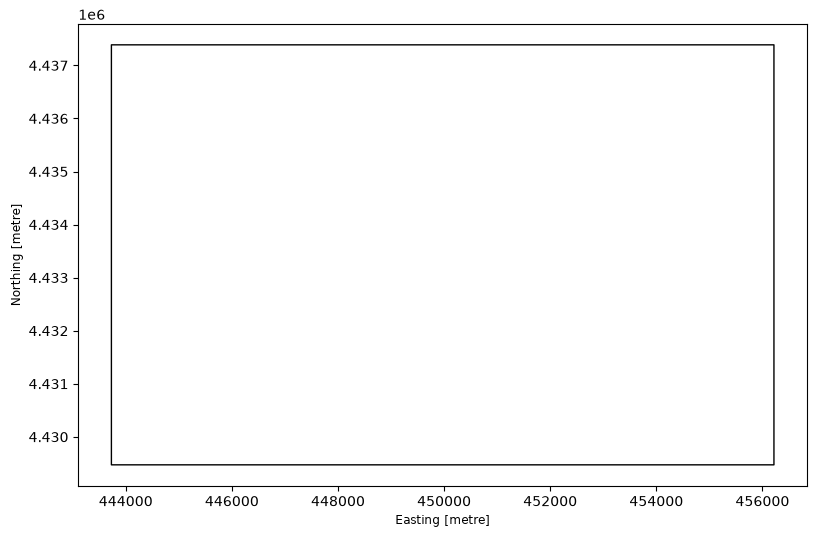

In [11]:
### plot the boundary
niwot_gdf.plot(figsize=(10, 6), edgecolor="black", facecolor="none")

### check projection
niwot_gdf.crs
### NAD_1983_UTM_Zone_13N

The above figure shows the Niwot ridge extent for the project area. The rectangular boundary shows Niwot Ridge and part of the green lakes valley.

In [12]:
### Need the boundary in 4326 for the API call
niwot_4326_gdf= niwot_gdf.to_crs(4326)
niwot_4326_gdf.crs


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [13]:

### plot the boundary with web tile images and a title
niwot_4326_gdf.hvplot(
    ### background tiles
    geo = True, tiles = 'EsriImagery',
    ### NO fill
    fill_color = None, line_color = 'white', line_width = 3,
    ### title
    title = 'Niwot Ridge Project Extent',
    ### size
    frame_width = 500
    
)

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]

## Exploring the AppEEARS API for NASA Earthdata access

Here I use a free [NASA Earthdata account](https://urs.earthdata.nasa.gov/home) with the [APPEEARS](https://appeears.earthdatacloud.nasa.gov/api/) API through `earthpy` to request [MODIS NDVI](https://www.earthdata.nasa.gov/data/catalog/lpcloud-mod13q1-006) data clipped to the Niwot Ridge boundary.

**Note:** It can take some time for Appeears to process your request - anything from a few minutes to a few hours depending on how busy they are. You can check your progress by:

1. Going to the [Appeears webpage](https://appeears.earthdatacloud.nasa.gov/)
2. Clicking the `Explore` tab
3. Logging in with your Earthdata account

In [14]:
### make a home for the data
project = earthpy.project.Project(dirname=str(ndvi_dir))  ### doesn't want a pathlib object, so convert to string
project.project_dir

WindowsPath('c:/users/nyca4176/repos/earth-data-portfolio/coding-assignments/04_final/data/01_ndvi')

In [15]:
### clear any cached AppEEARS task so a fresh request gets submitted
### (earthpy silently reuses the last task ID here, ignoring any new
### dates/year_range you've set, until this file is cleared)
task_id_path = pathlib.Path.home() / ".appeears_taskid"

if task_id_path.exists():
    task_id_path.unlink()

In [16]:
### make descriptive download key for the data you'll download
download_key = "niwot_modis_ndvi_july_2024_2027"

### initialize AppeearsDownloader for MODIS NDVI data
ndvi_downloader = eaapp.AppeearsDownloader(

    ### add download key
    download_key=download_key,

    ### define folder where data will download to
    project=project,

    ### specify remote sensing product
    product="MOD13Q1.061",

    ### and specific layer
    layer="_250m_16_days_NDVI",

    ### start date (adjust to the study period for your final project)
    start_date="07-01",

    ### end date (adjust to the study period for your final project)
    end_date="07-31",

    recurring=True,

    ### set year range (adjust to the study period for your final project)
    year_range=[2024, 2027],

    ### set polygon for area of interest
    polygon=niwot_4326_gdf,
)

In [ ]:
### re-do credentials if you are having issues
#ndvi_downloader.login(interactive=True, override=True)

### print a message with save location, number of files, file size
### snapshot what's already in the download folder before this download
existing_before = set(ndvi_downloader.download_dir.rglob("*"))

### download the prepared data (can be slow)
### change cache = False if you want to re-download the data with the same key (e.g., if you changed the year range)
ndvi_downloader.download_files(cache=False)

### report only the files this run added
new_files = [
    f for f in ndvi_downloader.download_dir.rglob("*")
    if f.is_file() and f not in existing_before
]

print(f"Data saved to: {ndvi_downloader.download_dir}")
print(f"New files this run: {len(new_files)}")
print(f"New data size: {sum(f.stat().st_size for f in new_files) / (1024**2):.2f} MB")

Credentials found using 'keyring' backend.


In [ ]:
### display the first tiff to check how it looks

import matplotlib.pyplot as plt
import rasterio

ndvi_tifs = sorted(ndvi_downloader.download_dir.rglob("*_NDVI_*.tif"))

with rasterio.open(ndvi_tifs[0]) as src:
    plt.imshow(src.read(1), cmap='BrBG')
    plt.show()

IndexError: list index out of range

In [ ]:
%store niwot_gdf boundary_dir ndvi_dir
### print code run date and time
print(f"Code Done as of: {pd.Timestamp.now()}")

Stored 'niwot_gdf' (GeoDataFrame)
Stored 'boundary_dir' (WindowsPath)
Stored 'ndvi_dir' (WindowsPath)
Code Done as of: 2026-11-26 01:16:45.749514
